In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob
import subprocess

In [378]:
sample_id = "3300061593"

df_mmseqs = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{sample_id}/{sample_id}.faa.mms2lca",
    sep = '\t'
)

df_mmseqs.head()

,contig_id,taxid,superkingdom,lineage,taxon,name
0,Ga0589705_0006950,1224,Bacteria,Bacteria;Pseudomonadota,phylum,Pseudomonadota
1,Ga0589705_0359909,1224,Bacteria,Bacteria;Pseudomonadota,phylum,Pseudomonadota
2,Ga0589705_0085846,1224,Bacteria,Bacteria;Pseudomonadota,phylum,Pseudomonadota
3,Ga0589705_0734282,1224,Bacteria,Bacteria;Pseudomonadota,phylum,Pseudomonadota
4,Ga0589705_0016740,1224,Bacteria,Bacteria;Pseudomonadota,phylum,Pseudomonadota


In [379]:
df_umap_coords = pd.DataFrame(
    columns = ['umap_0', 'umap_1'],
    data = np.load(f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/semibin/semibin_umap_coords.npy")
)

df_umap_coords['sample'] = sample_id
df_umap_coords.head()

,umap_0,umap_1,sample
0,2.142503,5.490051,3300061593
1,2.179856,5.438657,3300061593
2,1.985502,5.474591,3300061593
3,1.948355,5.653145,3300061593
4,2.019140,5.470024,3300061593


In [380]:
df_umap_coords.shape

(2830, 3)

In [381]:
df_semibin = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/semibin/contig_bins.tsv",
    sep = '\t', 
    names = ['contig_id', 'semibin_id'], 
    skiprows = 1
)

df_semibin.head()

,contig_id,semibin_id
0,Ga0589705_0000001,0
1,Ga0589705_0000002,0
2,Ga0589705_0000003,0
3,Ga0589705_0000004,0
4,Ga0589705_0000005,0


In [382]:
df_tiara = pd.read_csv(f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{sample_id}/{sample_id}.a.tiara.txt", 
    sep = '\t'
)

df_tiara.head()

,sequence_id,class_fst_stage,class_snd_stage
0,Ga0589705_0000001,bacteria,NaN
1,Ga0589705_0000002,bacteria,NaN
2,Ga0589705_0000003,bacteria,NaN
3,Ga0589705_0000004,bacteria,NaN
4,Ga0589705_0000005,bacteria,NaN


In [383]:
df = pd.merge(
    df_umap_coords, 
    df_semibin, 
    left_index = True, 
    right_index = True, 
    how = 'left'
)

df.shape

(2830, 5)

In [384]:
df = pd.merge(
    df, 
    df_tiara, 
    left_on = 'contig_id', 
    right_on = 'sequence_id', 
    how = 'left'
)

In [385]:
df = pd.merge(
    df, 
    df_mmseqs[['contig_id', 'name', 'superkingdom', 'lineage']], 
    on = 'contig_id', 
    how = 'left'
).fillna("None")

In [386]:
line = subprocess.check_output(
    f"grep -H '>' /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/metabat/* | tr -d '>'", 
    shell=True, text=True
)

mbins = [(x.split("/")[-1].split(":")[0], x.split("/")[-1].split(":")[1]) for x in line.split()]

df_metabat = pd.DataFrame(
    columns = ['metabat_id', 'contig_id'], 
    data = mbins
)

In [387]:
df = pd.merge(
    df, 
    df_metabat, 
    on = 'contig_id',
    how = 'left'
).fillna('None')


In [388]:
df['semibin_id'] = df.semibin_id.apply(lambda x: "semibin." + str(x))

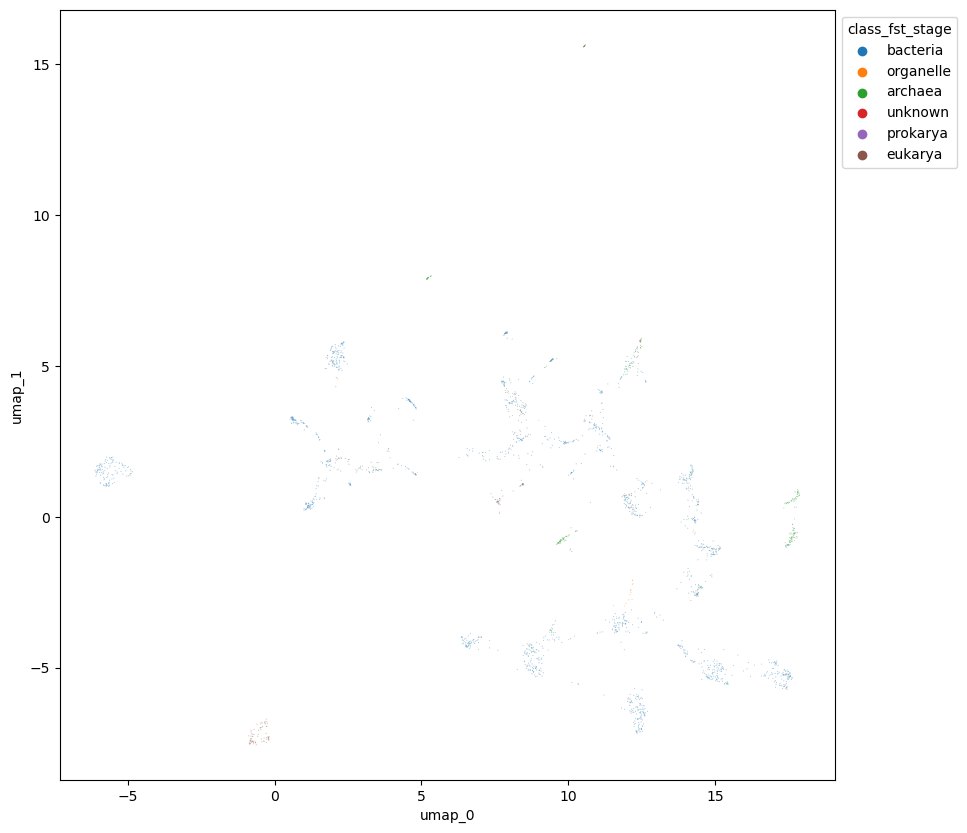

In [389]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df[
        ~df.superkingdom.isin(["None", "Unknown"])
    ], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    alpha = 0.5, 
    hue = 'class_fst_stage'
)

sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

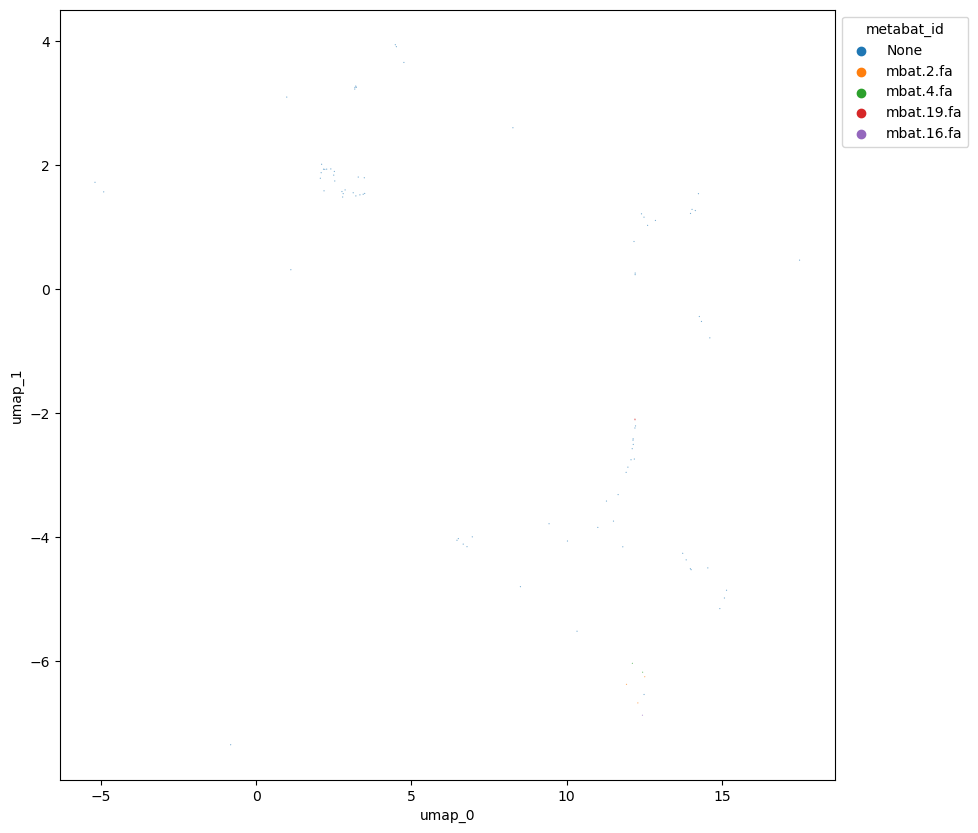

In [390]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df[
        df.superkingdom.isin(["Eukaryota"])
    ], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.75, 
    alpha = 0.66, 
    hue = 'metabat_id'
)

sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [391]:
# Ignore below this line ---------------------

In [392]:
# Lots of euks
3300055289, 3300060027, 3300060270, 

(3300055289, 3300060027, 3300060270)

In [393]:
# Not working
3300059831, 3300060025, 3300060026, 3300069050, 3300069124, 

(3300059831, 3300060025, 3300060026, 3300069050, 3300069124)

In [394]:
sample_id

'3300061593'

In [395]:
df[
    (
        (~df.class_fst_stage.isin(["bacteria", "archaea", "prokarya"]) &
         ~df.superkingdom.isin(["Bacteria", "Archaea"]))
    )# & 
    #((df.umap_1 > 10) & (df.umap_1 < 20) & (df.umap_0 > 5) & (df.umap_0 < 10))
].groupby('name').count().sort_values('umap_0', ascending = False).head(20)

,umap_0,umap_1,sample,contig_id,semibin_id,sequence_id,class_fst_stage,class_snd_stage,superkingdom,lineage,metabat_id
name,,,,,,,,,,,
None,62,62,62,62,62,62,62,62,62,62,62
unclassified Prasinovirus,17,17,17,17,17,17,17,17,17,17,17
Prasinovirus,14,14,14,14,14,14,14,14,14,14,14
Micromonas pusilla virus 12T,11,11,11,11,11,11,11,11,11,11,11
cellular organisms,11,11,11,11,11,11,11,11,11,11,11
Prymnesiophyceae,4,4,4,4,4,4,4,4,4,4,4
Phycodnaviridae,4,4,4,4,4,4,4,4,4,4,4
Eukaryota,3,3,3,3,3,3,3,3,3,3,3
Ochrophyta,2,2,2,2,2,2,2,2,2,2,2


In [396]:
krypto = (list(set(df[df.name == "Phaeocystis globosa"].lineage))[0].split(";")[2:] + 
    list(set(df[df.name == "Phaeocystis antarctica"].lineage))[0].split(";")[2:]
)

IndexError: list index out of range

In [ ]:
bac = list(set(df[df.name == "Fragilariopsis cylindrus CCMP1102"].lineage))[0].split(";")[2:]

In [ ]:
list(set(df[df.name == "Chrysochromulina parva"].lineage))[0].split(";")[2:]

In [ ]:
def get_euk_clade(n):
    if type(n) == int:
        return "oth"
    if n in(bac):
        return "bac"
    if n in(krypto):
        return "krypto"
    if n in(["Sar", "None", "Eukaryota", "cellular organisms"]):
        return "euk"
    return "oth"

df['euk_refined'] = df.name.apply(get_euk_clade)

In [ ]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df[
        ~df.superkingdom.isin(["None", "Unknown", "Bacteria", "Archaea", "Virus"]) & 
        ((df.umap_1 > 5) & (df.umap_1 < 7.6) & (df.umap_0 > -2.5) & (df.umap_0 < 3.5))
    ], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 4, 
    alpha = 0.8, 
    hue = 'euk_refined'
)

sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
df[
    ~df.superkingdom.isin(["None", "Unknown", "Bacteria", "Archaea", "Virus"]) & 
    ((df.umap_1 > 5) & (df.umap_1 < 7.6) & (df.umap_0 > -1) & (df.umap_0 < 2))
]#.sequence_id.to_csv("~/phaeocystis_a_3300060865.txt", index = False, header = False)

#.groupby('name').count().sort_values('umap_0', ascending = False).head(20)
